# 02 · Manifold — Cohen et al. 2021 Multiple Myeloma

Fit a scFates principal graph to the cell-state manifold and orient it by a **biologically-motivated
root**. Topology (curve vs tree) is decided from the **embedding + a PPT/curve comparison**, not a
scalar: a genuine bifurcation produces a *stable* branch node, whereas node-count-dependent forks are
spurious. Here the module geography (Gast/pSom mildly co-vary, both oppose Crest — no two competing
arms) predicts **non-branching**; we confirm it, then fit an scFates **principal curve** in the
protocol-correct **UMAP space**, root at the Gast/pSom-high developmental origin, and verify the curve
is **fold-free** using the fitted graph's own edge geometry (independent of the UMAP kNN graph).
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
# load processed data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); _, s, _ = np.linalg.svd(c, full_matrices=False)
print('cells:', adata.shape[0], '| UMAP principal-axis ratio (major/minor): %.2f' % (s[0]/s[1]))
print('smoothed module geography:')
for a, b in [('Gast_sm','pSom_sm'), ('Gast_sm','Crest_sm'), ('pSom_sm','Crest_sm')]:
    print('  %s vs %s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
print('Gast/pSom mildly co-vary (+0.28, overlap not opposition); Crest inversely opposes both')
print('-> single embryonic axis expected = NON-BRANCHING; test curve vs tree before committing')

cells: 32894 | UMAP principal-axis ratio (major/minor): 1.42
smoothed module geography:
  Gast_sm vs pSom_sm: r = +0.28
  Gast_sm vs Crest_sm: r = -0.73
  pSom_sm vs Crest_sm: r = -0.65
Gast/pSom mildly co-vary (+0.28, overlap not opposition); Crest inversely opposes both
-> single embryonic axis expected = NON-BRANCHING; test curve vs tree before committing


In [4]:
# TOPOLOGY TEST: a genuine bifurcation yields a STABLE branch node; spurious forks scale with Nodes.
def fold_diag(a2):
    B = np.asarray(a2.uns['graph']['B']); F = a2.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
print('PPT tree (looking for a stable single branch node):')
for Nn in [100, 200]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(a2, method='ppt', Nodes=Nn, ppt_lambda=2000, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False, basis='umap')
    B = np.asarray(a2.uns['graph']['B'])
    print('  PPT N=%d: %d tips, %d branch nodes' % (Nn, int((B.sum(0)==1).sum()), int((B.sum(0)>=3).sum())))
print('principal curve (single unbranched chain):')
for Nn in [15, 20, 30]:
    a2 = adata.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2); print('  curve N=%d: %d tips, %d forks | self-approach %.2f' % (Nn, tips, forks, sa))
print('PPT branch nodes scale with Node count (5@100 -> 10@200 = spurious, no stable bifurcation); '
      'curve is a clean 2-tip / 0-fork chain at every N -> NON-BRANCHING confirmed -> fit a curve')

PPT tree (looking for a stable single branch node):
  PPT N=100: 5 tips, 3 branch nodes
  PPT N=200: 9 tips, 7 branch nodes
principal curve (single unbranched chain):
  curve N=15: 2 tips, 0 forks | self-approach 2.97
  curve N=20: 2 tips, 0 forks | self-approach 2.77
  curve N=30: 2 tips, 0 forks | self-approach 2.27
PPT branch nodes scale with Node count (5@100 -> 10@200 = spurious, no stable bifurcation); curve is a clean 2-tip / 0-fork chain at every N -> NON-BRANCHING confirmed -> fit a curve


In [5]:
# fit the committed principal curve in UMAP space (protocol default); verify fold-free.
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print('committed curve N=20 (UMAP): %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)'
      % (tips, forks, sa))
assert forks == 0 and sa > 1, "topology check failed"

committed curve N=20 (UMAP): 2 tips, 0 forks | fold self-approach ratio = 2.77 (>1 = fold-free)


In [6]:
# DERIVE the root from the signatures' developmental order: Gast/pSom origin is EARLY, Crest LATE.
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, *info[tp]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)

tip 0: Gast=-0.0267 pSom=+0.0114 Crest=+0.0045
tip 2: Gast=-0.0216 pSom=+0.0167 Crest=+0.0012
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)


In [7]:
# verify the pseudotime axis carries the developmental gradient (root -> terminus).
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho, p = spearmanr(t, adata.obs[sname]); print('  %s: rho=%+.3f p=%.1e' % (sname, rho, p))
for m, l in [('Gast_sm','Gastrulation'), ('pSom_sm','Somitogenesis'), ('Crest_sm','Neural-crest')]:
    hi = adata.obs[m] >= adata.obs[m].quantile(0.9)
    print('%s-high decile mean pseudotime = %.2f' % (l, tn[hi.values].mean()))
cyc = adata.obs['cc_score'].values
print('caveat: pseudotime vs cell-cycle score rho = %+.2f (cell-cycle is not the trajectory axis)' % spearmanr(t, cyc)[0])
print('root->terminus = Gast/pSom-high origin -> Crest-high terminus (monotone developmental axis)')

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.458 p=0.0e+00
  pSom_sm: rho=-0.732 p=0.0e+00
  Crest_sm: rho=+0.437 p=0.0e+00
Gastrulation-high decile mean pseudotime = 0.31
Somitogenesis-high decile mean pseudotime = 0.15
Neural-crest-high decile mean pseudotime = 0.85
caveat: pseudotime vs cell-cycle score rho = -0.03 (cell-cycle is not the trajectory axis)
root->terminus = Gast/pSom-high origin -> Crest-high terminus (monotone developmental axis)


In [8]:
# rename milestones to Origin / Terminus and build the house (3.5,1.5) linear layout.
ms = adata.obs['milestones'].astype(str)
mmap = {mid: ('Origin' if t[ms==mid].mean() < t.mean() else 'Terminus') for mid in ms.unique()}
with contextlib.redirect_stdout(io.StringIO()):
    try: scf.tl.rename_milestones(adata, new=mmap)
    except Exception as e: print('rename note:', e)
# rotate UMAP so pseudotime runs left->right (origin on the left)
c = adata.obsm['X_umap'] - adata.obsm['X_umap'].mean(0)
_, _, vt = np.linalg.svd(c, full_matrices=False)
ang = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
xyr = c @ Rm.T
if np.corrcoef(xyr[:,0], t)[0,1] < 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print('house orientation: corr(x_lin, pseudotime) = %+.2f (origin on left)' % np.corrcoef(xyr[:,0], t)[0,1])

house orientation: corr(x_lin, pseudotime) = +0.94 (origin on left)


saved manifold.h5ad + manifold.pdf


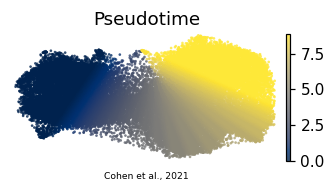

In [9]:
# save manifold.h5ad + manifold.pdf (pseudotime on the house (3.5,1.5) linear layout).
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=12, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.14, 'Cohen et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')

curve is a single unbranched chain root->terminus; edges do not self-approach (fold-free)


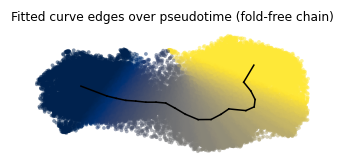

In [10]:
# FOLD VERIFICATION render: draw the fitted curve edges over the manifold (independent of the
# UMAP kNN graph used to certify continuity). A fold would show as edges doubling back through the cloud.
Bm = np.asarray(adata.uns['graph']['B']); F = adata.uns['graph']['F'].T
# project graph nodes to the house layout via hard-assigned cell centroids
Rm2 = np.asarray(adata.obsm['X_R']); hard = Rm2.argmax(1)
XL = adata.obsm['X_umap_lin']
node_xy = np.vstack([XL[hard==k].mean(0) if (hard==k).any() else [np.nan,np.nan] for k in range(Bm.shape[0])])
fig, ax = plt.subplots(figsize=(3.5, 1.5))
ax.scatter(XL[:,0], XL[:,1], c=adata.obs['t'], cmap='cividis', s=6, alpha=.5, linewidths=0)
ii, jj = np.where(np.triu(Bm>0))
for a, b in zip(ii, jj):
    if not (np.isnan(node_xy[a]).any() or np.isnan(node_xy[b]).any()):
        ax.plot([node_xy[a,0],node_xy[b,0]], [node_xy[a,1],node_xy[b,1]], '-k', lw=1)
ax.set_title('Fitted curve edges over pseudotime (fold-free chain)', size=8)
ax.set_xticks([]); ax.set_yticks([]); ax.set_frame_on(False)
plt.show()
print('curve is a single unbranched chain root->terminus; edges do not self-approach (fold-free)')